In [1]:
import numpy as np 
import pandas as pd 

IMPORT DATA SAMPEL

In [2]:
df = pd.read_csv("churn_fintech_sample.csv")

df.head() # show the data

,id_nasabah,usia,kota,lama_bergabung_bulan,login_30hari,transaksi_30hari,rata2_nilai_transaksi,rata2_saldo,hari_sejak_transaksi_terakhir,punya_paylater,komplain_90hari,skor_kepuasan,pakai_promo,jumlah_fitur_dipakai,churn
0,NSB100000,35,Lainnya,4,16,14,51800.0,1053700.0,8,0,0,4,1,3,0
1,NSB100001,23,Jabodetabek,33,8,10,25600.0,121700.0,4,0,1,3,1,4,0
2,NSB100002,39,Lainnya,38,11,8,64400.0,61000.0,0,0,0,4,0,3,0
3,NSB100003,40,Jabodetabek,12,9,13,46600.0,195700.0,5,0,0,3,0,1,0
4,NSB100004,18,Bandung,40,15,9,195800.0,61900.0,29,1,0,5,1,2,0


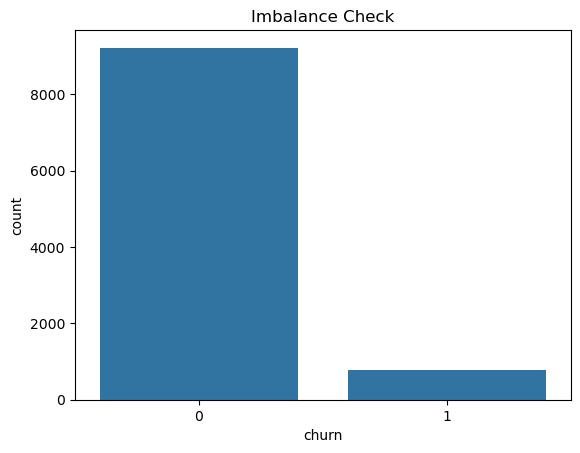

In [3]:
df['churn'].value_counts() # lihat ketidakseimbangan data

# visualisasikan

import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='churn', data=df)
plt.title('Imbalance Check')
plt.show()

In [4]:
#Cari data yang duplikat

print("Jumlah data yang duplikat:", df.duplicated().sum())

Jumlah data yang duplikat: 0


In [5]:
# Bagi data X dan Y -> pelanggan yang akan pergi

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, precision_score, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


X = df.drop(columns=['id_nasabah','kota','churn'])
y = df['churn']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, shuffle=False
)


# model masih baseline
model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
skor = model.predict(X_test)

print("Akurasi:", accuracy)
print("Precision:", round(precision_score(y_test, y_pred), 3)) 
print("Recall:", recall_score(y_test, y_pred))


# Kesimpulan baseline: akurasi tinggi hampir sama dengan "tebak semua bertahan",
# tetapi recall sangat rendah, jadi sebagian besar nasabah yang akan pergi tidak terdeteksi.

Akurasi: 0.9226666666666666
Precision: 0.593
Recall: 0.06751054852320675
